# Direct N-body Simulation with a GPU Quadtree

This notebook extends the direct N-body example with the Barnes-Hut approximation in two dimensions. It keeps the same disk initial condition, gravitational model, Velocity-Verlet update, and Python visualization. The animation is saved as a separate GIF file.

The exact direct method evaluates every target-source pair. Barnes-Hut groups distant sources into quadtree cells and replaces each accepted cell by its total mass at its center of mass. Nearby bodies, including bodies in the target's leaf cell, are evaluated individually.

The quadtree is built and traversed on the GPU. To keep the implementation readable, it uses a fixed-depth, dense node array: empty cells have zero mass, and the tree is rebuilt from the current positions every time step. The benchmark includes tree construction and force traversal, so it reflects the cost of the approximation pipeline rather than traversal alone.

Both notebooks create or reuse the same `nbody_initial_conditions.bin` file for the 512-body animation. They therefore begin from exactly the same positions, velocities, and masses. They are not expected to produce identical trajectories: Barnes-Hut approximates distant forces, and the notebook reports that force error relative to direct summation.

Use a Colab runtime with an NVIDIA GPU and CUDA Toolkit 13 or newer. The CUDA program performs the force calculation, tree construction, and time integration. Python only prepares the shared initial state, displays the saved positions, and writes the GIF.


## 1. Model and tree layout

The bodies start in the same disk configuration as the direct-summation notebook. Their motion is two-dimensional, while the softened Newtonian force retains the usual inverse-square distance law. With normalized units $G=1$, the acceleration is

$$
\mathbf a_i = G \sum_{j\ne i} m_j \frac{\mathbf x_j-\mathbf x_i}{(\|\mathbf x_j-\mathbf x_i\|^2+\varepsilon^2)^{3/2}}.
$$

The root square covers $[-8,8]\times[-8,8]$. The tree has eight subdivision levels, so its leaf grid is $256\times256$. Each occupied leaf stores a linked list of body indices and accumulates its total mass and mass-weighted position. Parent summaries are computed bottom-up. The array reserves all nodes in advance; empty cells take no traversal work because their mass is zero.

Barnes-Hut accepts an internal cell when its width divided by its distance from the target is less than the opening parameter $\theta$. Cells containing the target are always opened. Smaller $\theta$ generally improves force accuracy and increases work. The tree is rebuilt at every step because the bodies move. This fixed root is chosen to contain the example trajectory; a different simulation must choose a root that contains all positions, since body coordinates are mapped into the root square.


In [1]:
%%writefile nbody_quadtree.cu
#include <cuda_runtime.h>

#include <algorithm>
#include <cmath>
#include <chrono>
#include <cstdint>
#include <cstdlib>
#include <fstream>
#include <initializer_list>
#include <iostream>
#include <random>
#include <vector>

constexpr int BLOCK_SIZE = 256;
constexpr int TREE_DEPTH = 8;
constexpr int GRID_SIZE = 1 << TREE_DEPTH;
constexpr int LEAF_COUNT = 1 << (2 * TREE_DEPTH);
constexpr int NODE_COUNT = ((1 << (2 * (TREE_DEPTH + 1))) - 1) / 3;
constexpr double ROOT_MIN = -8.0;
constexpr double ROOT_SIZE = 16.0;
constexpr double GRAVITATIONAL_CONSTANT = 1.0;

#define CUDA_CHECK(call) do { \
    cudaError_t error = (call); \
    if (error != cudaSuccess) { \
        std::cerr << "CUDA error: " << cudaGetErrorString(error) \
                  << " at " << __FILE__ << ":" << __LINE__ << "\n"; \
        std::exit(EXIT_FAILURE); \
    } \
} while (0)

struct HostState {
    std::vector<double4_16a> position_mass;
    std::vector<double4_16a> velocity;
};

HostState make_disk(int n) {
    HostState state;
    state.position_mass.resize(n);
    state.velocity.resize(n);

    const double central_mass = 100.0;
    const double disk_mass = 1.0;
    state.position_mass[0] = make_double4_16a(0.0, 0.0, 0.0, central_mass);
    state.velocity[0] = make_double4_16a(0.0, 0.0, 0.0, 0.0);

    std::mt19937 generator(42);
    std::uniform_real_distribution<double> angle_distribution(
        0.0, 6.28318530717958647692);
    std::uniform_real_distribution<double> radius_squared_distribution(1.0, 16.0);
    const double particle_mass = disk_mass / (n - 1);

    for (int i = 1; i < n; ++i) {
        const double angle = angle_distribution(generator);
        const double radius = std::sqrt(radius_squared_distribution(generator));
        const double speed = std::sqrt(GRAVITATIONAL_CONSTANT * central_mass / radius);
        const double x = radius * std::cos(angle);
        const double y = radius * std::sin(angle);
        const double vx = -speed * std::sin(angle);
        const double vy = speed * std::cos(angle);
        state.position_mass[i] = make_double4_16a(x, y, 0.0, particle_mass);
        state.velocity[i] = make_double4_16a(vx, vy, 0.0, 0.0);
    }
    return state;
}

HostState load_initial_conditions(const char* filename, int expected_n) {
    std::ifstream input(filename, std::ios::binary);
    std::uint64_t stored_n = 0;
    if (!input.read(reinterpret_cast<char*>(&stored_n), sizeof(stored_n))
        || stored_n != static_cast<std::uint64_t>(expected_n)) {
        std::cerr << "Initial-condition file is missing or has the wrong body count.\n";
        std::exit(EXIT_FAILURE);
    }

    HostState state;
    state.position_mass.resize(expected_n);
    state.velocity.resize(expected_n);
    for (int i = 0; i < expected_n; ++i) {
        double values[7];
        if (!input.read(reinterpret_cast<char*>(values), sizeof(values))) {
            std::cerr << "Initial-condition file is incomplete.\n";
            std::exit(EXIT_FAILURE);
        }
        state.position_mass[i] = make_double4_16a(
            values[0], values[1], values[2], values[3]);
        state.velocity[i] = make_double4_16a(
            values[4], values[5], values[6], 0.0);
    }
    return state;
}

void direct_acceleration_cpu_into(
    const std::vector<double4_16a>& position_mass,
    double softening_squared,
    std::vector<double4_16a>& acceleration)
{
    const int n = static_cast<int>(position_mass.size());
    acceleration.resize(n);
    for (int i = 0; i < n; ++i) {
        const double4_16a target = position_mass[i];
        double ax = 0.0, ay = 0.0;
        for (int j = 0; j < n; ++j) {
            if (i == j) continue;
            const double4_16a source = position_mass[j];
            const double dx = source.x - target.x;
            const double dy = source.y - target.y;
            const double r2 = dx * dx + dy * dy + softening_squared;
            const double inv_r = 1.0 / std::sqrt(r2);
            const double scale = GRAVITATIONAL_CONSTANT * source.w
                               * inv_r * inv_r * inv_r;
            ax += scale * dx;
            ay += scale * dy;
        }
        acceleration[i] = make_double4_16a(ax, ay, 0.0, 0.0);
    }
}

std::vector<double4_16a> direct_acceleration_cpu(
    const std::vector<double4_16a>& position_mass, double softening_squared)
{
    std::vector<double4_16a> acceleration;
    direct_acceleration_cpu_into(position_mass, softening_squared, acceleration);
    return acceleration;
}

__host__ __device__ inline int level_offset(int level) {
    return ((1 << (2 * level)) - 1) / 3;
}

__host__ __device__ inline unsigned int spread_8_bits(unsigned int value) {
    value = (value | (value << 4)) & 0x0F0F;
    value = (value | (value << 2)) & 0x3333;
    value = (value | (value << 1)) & 0x5555;
    return value;
}

__host__ __device__ inline unsigned int morton_code(double x, double y) {
    int ix = static_cast<int>((x - ROOT_MIN) * GRID_SIZE / ROOT_SIZE);
    int iy = static_cast<int>((y - ROOT_MIN) * GRID_SIZE / ROOT_SIZE);
    ix = ix < 0 ? 0 : (ix >= GRID_SIZE ? GRID_SIZE - 1 : ix);
    iy = iy < 0 ? 0 : (iy >= GRID_SIZE ? GRID_SIZE - 1 : iy);
    return spread_8_bits(static_cast<unsigned int>(ix))
         | (spread_8_bits(static_cast<unsigned int>(iy)) << 1);
}

__global__ void build_leaves(const double4_16a* position_mass,
                             double4_16a* nodes,
                             int* leaf_head,
                             int* next_particle,
                             int n)
{
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;

    const double4_16a body = position_mass[i];
    const unsigned int leaf = morton_code(body.x, body.y);
    const int node = level_offset(TREE_DEPTH) + static_cast<int>(leaf);

    // Each body contributes its mass and first spatial moments to one leaf.
    atomicAdd(&nodes[node].x, body.w);
    atomicAdd(&nodes[node].y, body.w * body.x);
    atomicAdd(&nodes[node].z, body.w * body.y);

    // A linked list lets a leaf evaluate its nearby bodies exactly.
    next_particle[i] = atomicExch(&leaf_head[leaf], i);
}

__global__ void aggregate_level(double4_16a* nodes, int level, int parent_count) {
    const int code = blockIdx.x * blockDim.x + threadIdx.x;
    if (code >= parent_count) return;

    const int parent = level_offset(level) + code;
    const int first_child = level_offset(level + 1) + 4 * code;
    double mass = 0.0, moment_x = 0.0, moment_y = 0.0;
    for (int child = 0; child < 4; ++child) {
        const double4_16a value = nodes[first_child + child];
        mass += value.x;
        moment_x += value.y;
        moment_y += value.z;
    }
    nodes[parent] = make_double4_16a(mass, moment_x, moment_y, 0.0);
}

void build_quadtree(const double4_16a* d_position_mass,
                    double4_16a* d_nodes,
                    int* d_leaf_head,
                    int* d_next_particle,
                    int n)
{
    CUDA_CHECK(cudaMemset(d_nodes, 0, NODE_COUNT * sizeof(double4_16a)));
    CUDA_CHECK(cudaMemset(d_leaf_head, 0xff, LEAF_COUNT * sizeof(int)));

    const int blocks = (n + BLOCK_SIZE - 1) / BLOCK_SIZE;
    build_leaves<<<blocks, BLOCK_SIZE>>>(
        d_position_mass, d_nodes, d_leaf_head, d_next_particle, n);
    CUDA_CHECK(cudaGetLastError());

    // Reduce child-cell summaries upward, one level per kernel launch.
    for (int level = TREE_DEPTH - 1; level >= 0; --level) {
        const int parent_count = 1 << (2 * level);
        const int parent_blocks = (parent_count + BLOCK_SIZE - 1) / BLOCK_SIZE;
        aggregate_level<<<parent_blocks, BLOCK_SIZE>>>(d_nodes, level, parent_count);
        CUDA_CHECK(cudaGetLastError());
    }
}

struct CpuTree {
    std::vector<double4_16a> nodes;
    std::vector<int> leaf_head;
    std::vector<int> next_particle;
};

void build_quadtree_cpu(const std::vector<double4_16a>& position_mass,
                        CpuTree& tree)
{
    const int n = static_cast<int>(position_mass.size());
    tree.nodes.assign(NODE_COUNT, make_double4_16a(0.0, 0.0, 0.0, 0.0));
    tree.leaf_head.assign(LEAF_COUNT, -1);
    tree.next_particle.resize(n);

    for (int i = 0; i < n; ++i) {
        const double4_16a body = position_mass[i];
        const unsigned int leaf = morton_code(body.x, body.y);
        const int node = level_offset(TREE_DEPTH) + static_cast<int>(leaf);
        tree.nodes[node].x += body.w;
        tree.nodes[node].y += body.w * body.x;
        tree.nodes[node].z += body.w * body.y;
        tree.next_particle[i] = tree.leaf_head[leaf];
        tree.leaf_head[leaf] = i;
    }

    for (int level = TREE_DEPTH - 1; level >= 0; --level) {
        const int parent_count = 1 << (2 * level);
        for (int code = 0; code < parent_count; ++code) {
            const int parent = level_offset(level) + code;
            const int first_child = level_offset(level + 1) + 4 * code;
            double mass = 0.0, moment_x = 0.0, moment_y = 0.0;
            for (int child = 0; child < 4; ++child) {
                const double4_16a value = tree.nodes[first_child + child];
                mass += value.x;
                moment_x += value.y;
                moment_y += value.z;
            }
            tree.nodes[parent] = make_double4_16a(mass, moment_x, moment_y, 0.0);
        }
    }
}

void acceleration_barnes_hut_cpu(
    const std::vector<double4_16a>& position_mass,
    const CpuTree& tree,
    double softening_squared,
    double theta,
    std::vector<double4_16a>& acceleration)
{
    const int n = static_cast<int>(position_mass.size());
    acceleration.resize(n);
    const double theta_squared = theta * theta;

    for (int i = 0; i < n; ++i) {
        const double4_16a target = position_mass[i];
        const unsigned int target_leaf = morton_code(target.x, target.y);
        double ax = 0.0, ay = 0.0;
        int level = 0;
        unsigned int code = 0;
        bool finished = false;

        while (!finished) {
            const int node_index = level_offset(level) + static_cast<int>(code);
            const double4_16a cell = tree.nodes[node_index];
            if (cell.x > 0.0) {
                if (level == TREE_DEPTH) {
                    int j = tree.leaf_head[code];
                    while (j != -1) {
                        if (i != j) {
                            const double4_16a source = position_mass[j];
                            const double dx = source.x - target.x;
                            const double dy = source.y - target.y;
                            const double r2 = dx * dx + dy * dy + softening_squared;
                            const double inv_r = 1.0 / std::sqrt(r2);
                            const double scale = GRAVITATIONAL_CONSTANT * source.w
                                               * inv_r * inv_r * inv_r;
                            ax += scale * dx;
                            ay += scale * dy;
                        }
                        j = tree.next_particle[j];
                    }
                } else {
                    const unsigned int shift = 2 * (TREE_DEPTH - level);
                    const bool contains_target = (target_leaf >> shift) == code;
                    const double dx = cell.y / cell.x - target.x;
                    const double dy = cell.z / cell.x - target.y;
                    const double separation_squared = dx * dx + dy * dy;
                    const double softened_distance_squared =
                        separation_squared + softening_squared;
                    const double cell_size = ROOT_SIZE / (1 << level);
                    const bool accept_cell = !contains_target
                        && cell_size * cell_size
                           < theta_squared * separation_squared;
                    if (accept_cell) {
                        const double inv_r = 1.0 / std::sqrt(softened_distance_squared);
                        const double scale = GRAVITATIONAL_CONSTANT * cell.x
                                           * inv_r * inv_r * inv_r;
                        ax += scale * dx;
                        ay += scale * dy;
                    } else {
                        ++level;
                        code <<= 2;
                        continue;
                    }
                }
            }

            while (level > 0 && (code & 3u) == 3u) {
                code >>= 2;
                --level;
            }
            if (level == 0) finished = true;
            else ++code;
        }
        acceleration[i] = make_double4_16a(ax, ay, 0.0, 0.0);
    }
}

double benchmark_cpu_direct(const std::vector<double4_16a>& bodies,
                            int repetitions, double softening_squared)
{
    std::vector<double4_16a> acceleration(bodies.size());
    const auto start = std::chrono::steady_clock::now();
    for (int repetition = 0; repetition < repetitions; ++repetition) {
        direct_acceleration_cpu_into(bodies, softening_squared, acceleration);
    }
    const auto stop = std::chrono::steady_clock::now();
    double checksum = 0.0;
    for (const double4_16a& value : acceleration) checksum += value.x;
    if (!std::isfinite(checksum)) std::exit(EXIT_FAILURE);
    return std::chrono::duration<double, std::milli>(stop - start).count()
         / repetitions;
}

double benchmark_cpu_barnes_hut(const std::vector<double4_16a>& bodies,
                                int repetitions, double softening_squared,
                                double theta)
{
    CpuTree tree;
    std::vector<double4_16a> acceleration(bodies.size());
    const auto start = std::chrono::steady_clock::now();
    for (int repetition = 0; repetition < repetitions; ++repetition) {
        build_quadtree_cpu(bodies, tree);
        acceleration_barnes_hut_cpu(
            bodies, tree, softening_squared, theta, acceleration);
    }
    const auto stop = std::chrono::steady_clock::now();
    double checksum = 0.0;
    for (const double4_16a& value : acceleration) checksum += value.x;
    if (!std::isfinite(checksum)) std::exit(EXIT_FAILURE);
    return std::chrono::duration<double, std::milli>(stop - start).count()
         / repetitions;
}

__global__ void acceleration_direct_tiled(
    const double4_16a* __restrict__ position_mass,
    double4_16a* __restrict__ acceleration,
    int n,
    double softening_squared)
{
    __shared__ double4_16a source_tile[BLOCK_SIZE];
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    const int lane = threadIdx.x;
    double ax = 0.0, ay = 0.0;
    double4_16a target = make_double4_16a(0.0, 0.0, 0.0, 0.0);
    if (i < n) target = position_mass[i];

    const int tile_count_total = (n + BLOCK_SIZE - 1) / BLOCK_SIZE;
    for (int tile = 0; tile < tile_count_total; ++tile) {
        const int source_index = tile * BLOCK_SIZE + lane;
        source_tile[lane] = source_index < n
            ? position_mass[source_index]
            : make_double4_16a(0.0, 0.0, 0.0, 0.0);
        __syncthreads();

        const int count = min(BLOCK_SIZE, n - tile * BLOCK_SIZE);
        if (i < n) {
            for (int k = 0; k < count; ++k) {
                const int j = tile * BLOCK_SIZE + k;
                if (i == j) continue;
                const double4_16a source = source_tile[k];
                const double dx = source.x - target.x;
                const double dy = source.y - target.y;
                const double r2 = dx * dx + dy * dy + softening_squared;
                const double inv_r = 1.0 / sqrt(r2);
                const double scale = GRAVITATIONAL_CONSTANT * source.w
                                   * inv_r * inv_r * inv_r;
                ax += scale * dx;
                ay += scale * dy;
            }
        }
        __syncthreads();
    }
    if (i < n) acceleration[i] = make_double4_16a(ax, ay, 0.0, 0.0);
}

__global__ void acceleration_barnes_hut(
    const double4_16a* __restrict__ position_mass,
    const double4_16a* __restrict__ nodes,
    const int* __restrict__ leaf_head,
    const int* __restrict__ next_particle,
    double4_16a* __restrict__ acceleration,
    int n,
    double softening_squared,
    double theta)
{
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;

    const double4_16a target = position_mass[i];
    const unsigned int target_leaf = morton_code(target.x, target.y);
    const double theta_squared = theta * theta;
    double ax = 0.0, ay = 0.0;
    int level = 0;
    unsigned int code = 0;
    bool finished = false;

    // Stackless depth-first traversal of the implicit Morton-ordered tree.
    while (!finished) {
        const int node_index = level_offset(level) + static_cast<int>(code);
        const double4_16a cell = nodes[node_index];

        if (cell.x > 0.0) {
            if (level == TREE_DEPTH) {
                // Bodies in the same leaf are evaluated individually.
                int j = leaf_head[code];
                while (j != -1) {
                    if (i != j) {
                        const double4_16a source = position_mass[j];
                        const double dx = source.x - target.x;
                        const double dy = source.y - target.y;
                        const double r2 = dx * dx + dy * dy + softening_squared;
                        const double inv_r = 1.0 / sqrt(r2);
                        const double scale = GRAVITATIONAL_CONSTANT * source.w
                                           * inv_r * inv_r * inv_r;
                        ax += scale * dx;
                        ay += scale * dy;
                    }
                    j = next_particle[j];
                }
            } else {
                const unsigned int shift = 2 * (TREE_DEPTH - level);
                const bool contains_target = (target_leaf >> shift) == code;
                const double center_x = cell.y / cell.x;
                const double center_y = cell.z / cell.x;
                const double dx = center_x - target.x;
                const double dy = center_y - target.y;
                const double separation_squared = dx * dx + dy * dy;
                const double softened_distance_squared =
                    separation_squared + softening_squared;
                const double cell_size = ROOT_SIZE / (1 << level);
                const bool accept_cell = !contains_target
                    && cell_size * cell_size < theta_squared * separation_squared;

                if (accept_cell) {
                    const double inv_r = 1.0 / sqrt(softened_distance_squared);
                    const double scale = GRAVITATIONAL_CONSTANT * cell.x
                                       * inv_r * inv_r * inv_r;
                    ax += scale * dx;
                    ay += scale * dy;
                } else {
                    // Visit the first child; siblings are found when ascending.
                    ++level;
                    code <<= 2;
                    continue;
                }
            }
        }

        // Move to the next sibling, ascending past completed groups of four.
        while (level > 0 && (code & 3u) == 3u) {
            code >>= 2;
            --level;
        }
        if (level == 0) {
            finished = true;
        } else {
            ++code;
        }
    }

    acceleration[i] = make_double4_16a(ax, ay, 0.0, 0.0);
}

__global__ void update_positions(double4_16a* position_mass,
                                 const double4_16a* velocity,
                                 const double4_16a* acceleration,
                                 int n,
                                 double dt)
{
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;
    position_mass[i].x += velocity[i].x * dt
        + 0.5 * acceleration[i].x * dt * dt;
    position_mass[i].y += velocity[i].y * dt
        + 0.5 * acceleration[i].y * dt * dt;
}

__global__ void update_velocities(double4_16a* velocity,
                                  const double4_16a* acceleration,
                                  const double4_16a* new_acceleration,
                                  int n,
                                  double dt)
{
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= n) return;
    velocity[i].x += 0.5 * (acceleration[i].x + new_acceleration[i].x) * dt;
    velocity[i].y += 0.5 * (acceleration[i].y + new_acceleration[i].y) * dt;
}

void write_frame(std::ofstream& output,
                 const std::vector<double4_16a>& position_mass)
{
    for (const double4_16a& body : position_mass) {
        const double xy[2] = {body.x, body.y};
        output.write(reinterpret_cast<const char*>(xy), sizeof(xy));
    }
}

void run_animation(const HostState& initial, int steps, int save_every,
                   double dt, double softening_squared, double theta)
{
    HostState host = initial;
    const int n = static_cast<int>(host.position_mass.size());
    const int blocks = (n + BLOCK_SIZE - 1) / BLOCK_SIZE;
    double4_16a *d_position_mass = nullptr, *d_velocity = nullptr;
    double4_16a *d_acceleration = nullptr, *d_new_acceleration = nullptr;
    double4_16a *d_nodes = nullptr;
    int *d_leaf_head = nullptr, *d_next_particle = nullptr;

    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_position_mass), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_velocity), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_acceleration), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_new_acceleration), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_nodes), NODE_COUNT * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_leaf_head), LEAF_COUNT * sizeof(int)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_next_particle), n * sizeof(int)));
    CUDA_CHECK(cudaMemcpy(d_position_mass, host.position_mass.data(), n * sizeof(double4_16a), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_velocity, host.velocity.data(), n * sizeof(double4_16a), cudaMemcpyHostToDevice));

    build_quadtree(d_position_mass, d_nodes, d_leaf_head, d_next_particle, n);
    acceleration_barnes_hut<<<blocks, BLOCK_SIZE>>>(
        d_position_mass, d_nodes, d_leaf_head, d_next_particle,
        d_acceleration, n, softening_squared, theta);
    CUDA_CHECK(cudaGetLastError());

    const std::uint64_t frame_count =
        1 + (steps + save_every - 1) / save_every;
    std::ofstream output("trajectory_quadtree.bin", std::ios::binary);
    if (!output) {
        std::cerr << "Could not open trajectory output file.\n";
        std::exit(EXIT_FAILURE);
    }
    const std::uint64_t header[2] =
        {static_cast<std::uint64_t>(n), frame_count};
    output.write(reinterpret_cast<const char*>(header), sizeof(header));

    std::vector<double4_16a> host_positions(n);
    CUDA_CHECK(cudaMemcpy(host_positions.data(), d_position_mass,
                          n * sizeof(double4_16a), cudaMemcpyDeviceToHost));
    write_frame(output, host_positions);

    for (int step = 1; step <= steps; ++step) {
        update_positions<<<blocks, BLOCK_SIZE>>>(
            d_position_mass, d_velocity, d_acceleration, n, dt);
        CUDA_CHECK(cudaGetLastError());
        build_quadtree(d_position_mass, d_nodes, d_leaf_head, d_next_particle, n);
        acceleration_barnes_hut<<<blocks, BLOCK_SIZE>>>(
            d_position_mass, d_nodes, d_leaf_head, d_next_particle,
            d_new_acceleration, n, softening_squared, theta);
        CUDA_CHECK(cudaGetLastError());
        update_velocities<<<blocks, BLOCK_SIZE>>>(
            d_velocity, d_acceleration, d_new_acceleration, n, dt);
        CUDA_CHECK(cudaGetLastError());
        std::swap(d_acceleration, d_new_acceleration);

        if (step % save_every == 0 || step == steps) {
            CUDA_CHECK(cudaMemcpy(host_positions.data(), d_position_mass,
                                  n * sizeof(double4_16a), cudaMemcpyDeviceToHost));
            write_frame(output, host_positions);
        }
    }
    CUDA_CHECK(cudaDeviceSynchronize());
    output.close();

    CUDA_CHECK(cudaFree(d_next_particle));
    CUDA_CHECK(cudaFree(d_leaf_head));
    CUDA_CHECK(cudaFree(d_nodes));
    CUDA_CHECK(cudaFree(d_new_acceleration));
    CUDA_CHECK(cudaFree(d_acceleration));
    CUDA_CHECK(cudaFree(d_velocity));
    CUDA_CHECK(cudaFree(d_position_mass));
}

float benchmark_direct(const std::vector<double4_16a>& bodies,
                       int repetitions, double softening_squared)
{
    const int n = static_cast<int>(bodies.size());
    const int blocks = (n + BLOCK_SIZE - 1) / BLOCK_SIZE;
    double4_16a *d_position_mass = nullptr, *d_acceleration = nullptr;
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_position_mass), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_acceleration), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMemcpy(d_position_mass, bodies.data(), n * sizeof(double4_16a), cudaMemcpyHostToDevice));
    for (int k = 0; k < 3; ++k) {
        acceleration_direct_tiled<<<blocks, BLOCK_SIZE>>>(
            d_position_mass, d_acceleration, n, softening_squared);
    }
    CUDA_CHECK(cudaDeviceSynchronize());

    cudaEvent_t start, stop;
    CUDA_CHECK(cudaEventCreate(&start));
    CUDA_CHECK(cudaEventCreate(&stop));
    CUDA_CHECK(cudaEventRecord(start));
    for (int k = 0; k < repetitions; ++k) {
        acceleration_direct_tiled<<<blocks, BLOCK_SIZE>>>(
            d_position_mass, d_acceleration, n, softening_squared);
    }
    CUDA_CHECK(cudaEventRecord(stop));
    CUDA_CHECK(cudaEventSynchronize(stop));
    float total_ms = 0.0f;
    CUDA_CHECK(cudaEventElapsedTime(&total_ms, start, stop));
    CUDA_CHECK(cudaEventDestroy(start));
    CUDA_CHECK(cudaEventDestroy(stop));
    CUDA_CHECK(cudaFree(d_acceleration));
    CUDA_CHECK(cudaFree(d_position_mass));
    return total_ms / repetitions;
}

float benchmark_barnes_hut(const std::vector<double4_16a>& bodies,
                           int repetitions, double softening_squared,
                           double theta)
{
    const int n = static_cast<int>(bodies.size());
    const int blocks = (n + BLOCK_SIZE - 1) / BLOCK_SIZE;
    double4_16a *d_position_mass = nullptr, *d_acceleration = nullptr;
    double4_16a *d_nodes = nullptr;
    int *d_leaf_head = nullptr, *d_next_particle = nullptr;
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_position_mass), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_acceleration), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_nodes), NODE_COUNT * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_leaf_head), LEAF_COUNT * sizeof(int)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_next_particle), n * sizeof(int)));
    CUDA_CHECK(cudaMemcpy(d_position_mass, bodies.data(), n * sizeof(double4_16a), cudaMemcpyHostToDevice));

    for (int k = 0; k < 3; ++k) {
        build_quadtree(d_position_mass, d_nodes, d_leaf_head, d_next_particle, n);
        acceleration_barnes_hut<<<blocks, BLOCK_SIZE>>>(
            d_position_mass, d_nodes, d_leaf_head, d_next_particle,
            d_acceleration, n, softening_squared, theta);
        CUDA_CHECK(cudaGetLastError());
    }
    CUDA_CHECK(cudaDeviceSynchronize());

    cudaEvent_t start, stop;
    CUDA_CHECK(cudaEventCreate(&start));
    CUDA_CHECK(cudaEventCreate(&stop));
    CUDA_CHECK(cudaEventRecord(start));
    for (int k = 0; k < repetitions; ++k) {
        build_quadtree(d_position_mass, d_nodes, d_leaf_head, d_next_particle, n);
        acceleration_barnes_hut<<<blocks, BLOCK_SIZE>>>(
            d_position_mass, d_nodes, d_leaf_head, d_next_particle,
            d_acceleration, n, softening_squared, theta);
        CUDA_CHECK(cudaGetLastError());
    }
    CUDA_CHECK(cudaEventRecord(stop));
    CUDA_CHECK(cudaEventSynchronize(stop));
    float total_ms = 0.0f;
    CUDA_CHECK(cudaEventElapsedTime(&total_ms, start, stop));
    CUDA_CHECK(cudaEventDestroy(start));
    CUDA_CHECK(cudaEventDestroy(stop));
    CUDA_CHECK(cudaFree(d_next_particle));
    CUDA_CHECK(cudaFree(d_leaf_head));
    CUDA_CHECK(cudaFree(d_nodes));
    CUDA_CHECK(cudaFree(d_acceleration));
    CUDA_CHECK(cudaFree(d_position_mass));
    return total_ms / repetitions;
}

int main() {
    constexpr double dt = 0.001;
    constexpr double softening_squared = 0.02 * 0.02;
    constexpr double theta = 0.5;

    // Compare exact GPU forces with the CPU reference, then report the
    // approximation error of Barnes-Hut relative to the exact CPU forces.
    HostState validation = load_initial_conditions(
        "nbody_initial_conditions.bin", 512);
    const auto cpu_acceleration =
        direct_acceleration_cpu(validation.position_mass, softening_squared);
    CpuTree cpu_tree;
    build_quadtree_cpu(validation.position_mass, cpu_tree);
    std::vector<double4_16a> cpu_tree_acceleration;
    acceleration_barnes_hut_cpu(validation.position_mass, cpu_tree,
                                softening_squared, theta,
                                cpu_tree_acceleration);
    const int n = static_cast<int>(validation.position_mass.size());
    const int blocks = (n + BLOCK_SIZE - 1) / BLOCK_SIZE;
    double4_16a *d_position_mass = nullptr, *d_direct = nullptr, *d_tree = nullptr;
    double4_16a *d_nodes = nullptr;
    int *d_leaf_head = nullptr, *d_next_particle = nullptr;
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_position_mass), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_direct), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_tree), n * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_nodes), NODE_COUNT * sizeof(double4_16a)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_leaf_head), LEAF_COUNT * sizeof(int)));
    CUDA_CHECK(cudaMalloc(reinterpret_cast<void**>(&d_next_particle), n * sizeof(int)));
    CUDA_CHECK(cudaMemcpy(d_position_mass, validation.position_mass.data(),
                          n * sizeof(double4_16a), cudaMemcpyHostToDevice));

    acceleration_direct_tiled<<<blocks, BLOCK_SIZE>>>(
        d_position_mass, d_direct, n, softening_squared);
    CUDA_CHECK(cudaGetLastError());
    build_quadtree(d_position_mass, d_nodes, d_leaf_head, d_next_particle, n);
    acceleration_barnes_hut<<<blocks, BLOCK_SIZE>>>(
        d_position_mass, d_nodes, d_leaf_head, d_next_particle,
        d_tree, n, softening_squared, theta);
    CUDA_CHECK(cudaGetLastError());
    std::vector<double4_16a> direct_gpu(n), tree_gpu(n);
    CUDA_CHECK(cudaMemcpy(direct_gpu.data(), d_direct, n * sizeof(double4_16a), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(tree_gpu.data(), d_tree, n * sizeof(double4_16a), cudaMemcpyDeviceToHost));

    double direct_max_error = 0.0, gpu_error_squared = 0.0;
    double cpu_error_squared = 0.0, cpu_gpu_tree_error_squared = 0.0;
    double exact_squared = 0.0;
    for (int i = 0; i < n; ++i) {
        for (int axis = 0; axis < 2; ++axis) {
            const double exact = axis == 0 ? cpu_acceleration[i].x : cpu_acceleration[i].y;
            const double gpu = axis == 0 ? direct_gpu[i].x : direct_gpu[i].y;
            const double approximate = axis == 0 ? tree_gpu[i].x : tree_gpu[i].y;
            direct_max_error = std::max(direct_max_error, std::abs(exact - gpu));
            const double cpu_approximate = axis == 0
                ? cpu_tree_acceleration[i].x : cpu_tree_acceleration[i].y;
            gpu_error_squared += (exact - approximate) * (exact - approximate);
            cpu_error_squared += (exact - cpu_approximate) * (exact - cpu_approximate);
            cpu_gpu_tree_error_squared +=
                (approximate - cpu_approximate) * (approximate - cpu_approximate);
            exact_squared += exact * exact;
        }
    }
    std::cout << "Force check, N=512, theta=" << theta << "\n";
    std::cout << "Direct tiled GPU vs CPU max absolute error: "
              << direct_max_error << (direct_max_error < 1e-9 ? "  PASS\n" : "  CHECK\n");
    std::cout << "CPU Barnes-Hut relative RMS force error vs direct: "
              << std::sqrt(cpu_error_squared / exact_squared) << "\n";
    std::cout << "GPU Barnes-Hut relative RMS force error vs direct: "
              << std::sqrt(gpu_error_squared / exact_squared) << "\n";
    std::cout << "CPU/GPU Barnes-Hut relative RMS difference: "
              << std::sqrt(cpu_gpu_tree_error_squared / exact_squared) << "\n";

    CUDA_CHECK(cudaFree(d_next_particle));
    CUDA_CHECK(cudaFree(d_leaf_head));
    CUDA_CHECK(cudaFree(d_nodes));
    CUDA_CHECK(cudaFree(d_tree));
    CUDA_CHECK(cudaFree(d_direct));
    CUDA_CHECK(cudaFree(d_position_mass));

    constexpr int repetitions = 5;
    constexpr int cpu_repetitions = 2;
    HostState benchmark_input = make_disk(2048);
    const double cpu_direct_ms = benchmark_cpu_direct(
        benchmark_input.position_mass, cpu_repetitions, softening_squared);
    const double cpu_tree_ms = benchmark_cpu_barnes_hut(
        benchmark_input.position_mass, cpu_repetitions, softening_squared, theta);
    const float gpu_direct_ms = benchmark_direct(
        benchmark_input.position_mass, repetitions, softening_squared);
    const float gpu_tree_ms = benchmark_barnes_hut(
        benchmark_input.position_mass, repetitions, softening_squared, theta);
    std::cout << "\nCPU and GPU force timings, N=2048 (CPU average over "
              << cpu_repetitions << ", GPU average over " << repetitions << ")\n";
    std::cout << "CPU direct: " << cpu_direct_ms << " ms/evaluation\n";
    std::cout << "GPU direct tiled: " << gpu_direct_ms << " ms/evaluation\n";
    std::cout << "CPU Barnes-Hut build + force: " << cpu_tree_ms << " ms/evaluation\n";
    std::cout << "GPU Barnes-Hut build + force: " << gpu_tree_ms << " ms/evaluation\n";
    std::cout << "CPU-direct/GPU-direct ratio: " << cpu_direct_ms / gpu_direct_ms << "\n";
    std::cout << "CPU-tree/GPU-tree ratio: " << cpu_tree_ms / gpu_tree_ms << "\n";

    constexpr int larger_n = 8192;
    HostState larger_input = make_disk(larger_n);
    const float larger_direct_ms = benchmark_direct(
        larger_input.position_mass, repetitions, softening_squared);
    const float larger_tree_ms = benchmark_barnes_hut(
        larger_input.position_mass, repetitions, softening_squared, theta);
    std::cout << "\nGPU scaling comparison, N=" << larger_n
              << " (average over " << repetitions << " timed runs)\n";
    std::cout << "GPU direct tiled: " << larger_direct_ms << " ms/evaluation\n";
    std::cout << "GPU Barnes-Hut build + force: " << larger_tree_ms << " ms/evaluation\n";
    std::cout << "Direct/tree time ratio: " << larger_direct_ms / larger_tree_ms << "\n";

    constexpr int animation_steps = 1200;
    constexpr int save_every = 10;
    const HostState animation_initial = load_initial_conditions(
        "nbody_initial_conditions.bin", 512);
    run_animation(animation_initial, animation_steps, save_every,
                  dt, softening_squared, theta);
    std::cout << "\nSaved "
              << 1 + (animation_steps + save_every - 1) / save_every
              << " frames to trajectory_quadtree.bin\n";
    return 0;
}


Writing nbody_quadtree.cu


## 2. Create or reuse the shared initial condition

Run this cell in both the direct and quadtree notebooks. It creates a pseudorandom disk with seed 42 the first time and saves it to `nbody_initial_conditions.bin`. The other notebook reuses the file if it is present. To make a new sample, remove the file and change `random_seed`; use the resulting file in both notebooks.


In [2]:
from pathlib import Path
import numpy as np
import hashlib

body_count = 512
random_seed = 42
initial_file = Path("nbody_initial_conditions.bin")

if not initial_file.exists():
    rng = np.random.default_rng(random_seed)
    central_mass = 100.0
    disk_mass = 1.0
    angle = rng.uniform(0.0, 2.0 * np.pi, body_count - 1)
    radius = np.sqrt(rng.uniform(1.0, 16.0, body_count - 1))
    speed = np.sqrt(central_mass / radius)

    initial = np.zeros((body_count, 7), dtype=np.float64)
    initial[0, 3] = central_mass
    initial[1:, 0] = radius * np.cos(angle)
    initial[1:, 1] = radius * np.sin(angle)
    initial[1:, 3] = disk_mass / (body_count - 1)
    initial[1:, 4] = -speed * np.sin(angle)
    initial[1:, 5] = speed * np.cos(angle)

    with initial_file.open("wb") as file:
        np.asarray([body_count], dtype=np.uint64).tofile(file)
        initial.tofile(file)
    print(f"Created {initial_file} with seed {random_seed}.")
with initial_file.open("rb") as file:
    stored_count = np.fromfile(file, dtype=np.uint64, count=1)
    stored = np.fromfile(file, dtype=np.float64)
if stored_count.size != 1 or stored_count[0] != body_count:
    raise ValueError(f"{initial_file} has the wrong body count.")
if stored.size != body_count * 7:
    raise ValueError(f"{initial_file} has an unexpected size.")
print(f"Using shared initial condition from {initial_file}.")
print("Initial-condition SHA-256:", hashlib.sha256(initial_file.read_bytes()).hexdigest())


Created nbody_initial_conditions.bin with seed 42.
Using shared initial condition from nbody_initial_conditions.bin.
Initial-condition SHA-256: 09e8c2457c7875790a5379afe8b6a8575963839adad5c803bcf83d4c56ec0866


## 3. Compile and run the CUDA program

The program compares exact direct and approximate Barnes-Hut accelerations against CPU references using the shared initial state. It benchmarks CPU direct, GPU direct, CPU Barnes-Hut, and GPU Barnes-Hut at $N=2048$. The GPU scaling comparison also tests $N=8192$. CPU/GPU Barnes-Hut timings include tree construction; transfers are outside the timed section. The final run evolves the shared 512-body state and writes snapshots to `trajectory_quadtree.bin`.


In [3]:
!nvcc -O3 -std=c++17 -arch=native nbody_quadtree.cu -o nbody_quadtree
!./nbody_quadtree


Force check, N=512, theta=0.5
Direct tiled GPU vs CPU max absolute error: 4.26326e-14  PASS
CPU Barnes-Hut relative RMS force error vs direct: 6.06952e-05
GPU Barnes-Hut relative RMS force error vs direct: 6.06952e-05
CPU/GPU Barnes-Hut relative RMS difference: 1.56764e-16

CPU and GPU force timings, N=2048 (CPU average over 2, GPU average over 5)
CPU direct: 19.7889 ms/evaluation
GPU direct tiled: 9.15993 ms/evaluation
CPU Barnes-Hut build + force: 12.6355 ms/evaluation
GPU Barnes-Hut build + force: 3.43466 ms/evaluation
CPU-direct/GPU-direct ratio: 2.16038
CPU-tree/GPU-tree ratio: 3.67881

GPU scaling comparison, N=8192 (average over 5 timed runs)
GPU direct tiled: 19.2069 ms/evaluation
GPU Barnes-Hut build + force: 2.41459 ms/evaluation
Direct/tree time ratio: 7.9545

Saved 121 frames to trajectory_quadtree.bin


## 4. Inspect the quadtree partition

This small Python plot overlays the first three subdivision levels of the root square on the initial particle distribution. The full GPU tree is deeper; empty nodes are skipped during traversal. The grid lines show how a body is assigned to successively smaller cells using its Morton code.


Loaded 121 frames for 512 bodies.


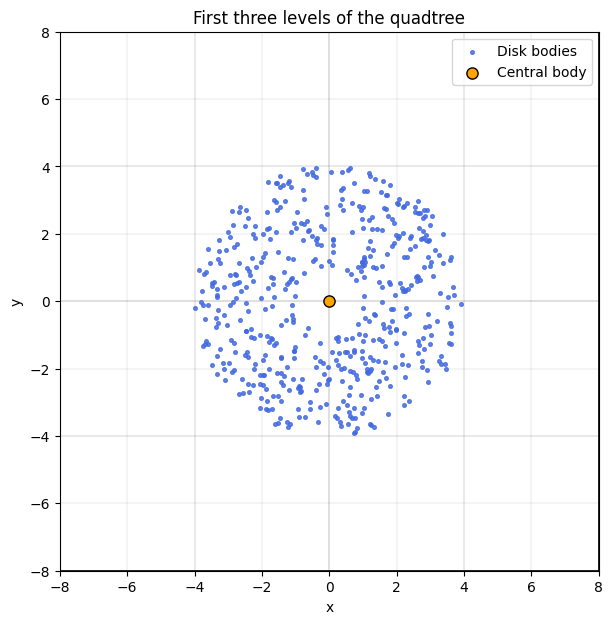

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

with open("trajectory_quadtree.bin", "rb") as file:
    n_bodies, n_frames = np.fromfile(file, dtype=np.uint64, count=2)
    trajectory = np.fromfile(file, dtype=np.float64)

trajectory = trajectory.reshape(int(n_frames), int(n_bodies), 2)
print(f"Loaded {n_frames} frames for {n_bodies} bodies.")

root_min = -8.0
root_size = 16.0
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(trajectory[0, 1:, 0], trajectory[0, 1:, 1], s=7,
           color="royalblue", alpha=0.8, label="Disk bodies")
ax.scatter(trajectory[0, 0, 0], trajectory[0, 0, 1], s=65,
           color="orange", edgecolor="black", label="Central body", zorder=3)

# Draw the logical grid through level 3; finer levels are omitted for clarity.
for level in range(1, 4):
    divisions = 2 ** level
    for k in range(divisions + 1):
        coordinate = root_min + k * root_size / divisions
        ax.plot([coordinate, coordinate], [root_min, root_min + root_size],
                color="gray", linewidth=0.35, alpha=0.35, zorder=0)
        ax.plot([root_min, root_min + root_size], [coordinate, coordinate],
                color="gray", linewidth=0.35, alpha=0.35, zorder=0)
ax.add_patch(Rectangle((root_min, root_min), root_size, root_size,
                       fill=False, edgecolor="black", linewidth=1.2))
ax.set_xlim(root_min, root_min + root_size)
ax.set_ylim(root_min, root_min + root_size)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("First three levels of the quadtree")
ax.legend(loc="upper right")
plt.show()


## 5. Save the animation as a GIF

The trajectory contains 121 snapshots. This cell creates `nbody_quadtree_animation.gif` in the notebook's working directory and displays only a link to the file. Add the GIF to the repository beside the notebook if you want it available from GitHub.


In [5]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import FileLink, display

fig, ax = plt.subplots(figsize=(6, 6))
points = ax.scatter(trajectory[0, :, 0], trajectory[0, :, 1],
                    s=5, color="royalblue")
central_body, = ax.plot(
    [trajectory[0, 0, 0]], [trajectory[0, 0, 1]],
    marker="o", linestyle="", markersize=9, color="orange",
    label="Central body"
)
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(-4.5, 4.5)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper right")
ax.set_title("Barnes-Hut N-body simulation")

def update(frame):
    points.set_offsets(trajectory[frame])
    central_body.set_data([trajectory[frame, 0, 0]],
                          [trajectory[frame, 0, 1]])
    ax.set_title(f"Barnes-Hut N-body simulation — frame {frame + 1}/{len(trajectory)}")
    return points, central_body,

animation = FuncAnimation(
    fig, update, frames=len(trajectory), interval=50, blit=True
)
animation_file = "nbody_quadtree_animation.gif"
animation.save(animation_file, writer=PillowWriter(fps=20), dpi=100)
plt.close(fig)
print(f"Saved animation to {animation_file}")
display(FileLink(animation_file))


Saved animation to nbody_quadtree_animation.gif


/content/nbody_quadtree_animation.gif

## 6. What to observe

The direct tiled kernel gives the exact softened force and is a useful GPU baseline. Barnes-Hut reduces the number of distant interactions by replacing groups of sources with cell summaries. The printed force error makes the accuracy cost visible; the two benchmark sizes show how tree construction overhead affects the crossover.

This implementation keeps the quadtree fixed-depth to make allocation and traversal easy to follow. It rebuilds the tree entirely on the GPU and includes that work in its timing. The asymptotic work is typically close to $O(N\log N)$ for a well-distributed system, but the actual cost depends on the distribution, opening parameter, tree depth, and hardware. In the worst case, many cells must be opened and the work can approach the direct method.
